In [48]:
print("# Tugas 1 Machine Learning - Data Preprocessing #")
print("===============================================")
print("Nama  : Lena Supriatina")
print("NIM   : 055321261")
print("Prodi : Sains Data")
print("===============================================")
print("  ")

# Tugas 1 Machine Learning - Data Preprocessing #
Nama  : Lena Supriatina
NIM   : 055321261
Prodi : Sains Data
  


1. Load Dataset

In [49]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [50]:
# Mengunggah file dari komputer karena menggunakan Google Colab
from google.colab import files
uploaded = files.upload()

Saving dataset_tugas1_preprocessing.csv to dataset_tugas1_preprocessing (2).csv


In [51]:
# Membaca dataset
df = pd.read_csv("dataset_tugas1_preprocessing.csv")

# Menampilkan 5 baris pertama
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


2. Explorasi Data Awal (EDA)

In [52]:
# Melihat ukuran dataset: jumlah baris dan kolom
print("Ukuran dataset:", df.shape)

Ukuran dataset: (99, 8)


In [53]:
# Melihat struktur lengkap (nama kolom, jumlah data, dan tipe data)
print("\nStruktur data:")
print(df.info())


Struktur data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB
None


In [54]:
# Menampilkan jumlah nilai hilang per kolom
print("\nJumlah nilai hilang per kolom:")
print(df.isnull().sum())


Jumlah nilai hilang per kolom:
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64


In [55]:
# Menyajikan statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe())


Statistik deskriptif:


,Umur
count,90.000000
mean,23.366667
std,3.763963
min,18.000000
25%,20.000000
50%,23.000000
75%,26.000000
max,30.000000


3. Menangani missing values
  

In [56]:
# 1. Menghapus baris yang mempunyai missing values lebih dari 1 (Listwise Deletion)
df = pd.read_csv("dataset_tugas1_preprocessing.csv")

print("Jumlah baris sebelum penghapusan:", len(df))
df.dropna(thresh=len(df.columns)-1, inplace=True)
print("Jumlah baris setelah penghapusan:", len(df))

Jumlah baris sebelum penghapusan: 99
Jumlah baris setelah penghapusan: 96


In [57]:
# Menampilkan 5 baris pertama setelah dilakukan listwise deletion
print("\nTampilan 5 baris pertama setelah listwise deletion")
df.head()


Tampilan 5 baris pertama setelah listwise deletion


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0
5,MH006,Gita,Perempuan,Teknik Komputer,Aktif,C,2021/10/15,20.0


In [58]:
# 2. Imputasi - mean/median/modus
print("\nMissing values sebelum imputasi:")
print(df[["Nilai_Akhir", "Umur"]].isnull().sum())

# Imputasi median untuk Umur
df["Umur"] = df["Umur"].fillna(df["Umur"].median())

# Mencari modus Nilai_Akhir
NA_mode = df["Nilai_Akhir"].mode()
nilai_akhir_fill = NA_mode.iloc[0] if not NA_mode.empty else None

# Imputasi modus untuk Nilai_Akhir
df["Nilai_Akhir"] = df["Nilai_Akhir"].fillna(nilai_akhir_fill)

# Memeriksa hasil imputasi
print("\nMissing values setelah imputasi:")
print(df[["Nilai_Akhir", "Umur"]].isnull().sum())

display(df.head())


Missing values sebelum imputasi:
Nilai_Akhir    26
Umur            6
dtype: int64

Missing values setelah imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,C,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0
5,MH006,Gita,Perempuan,Teknik Komputer,Aktif,C,2021/10/15,20.0


4. Normalisasi format tanggal

In [59]:
# Mengubah kolom tanggal menjadi datetime
df["Tanggal_Ujian"] = pd.to_datetime(
    df["Tanggal_Ujian"],
    errors="coerce",
    dayfirst=True)

# Memeriksa hasil konversi
print(df["Tanggal_Ujian"].head())
print("\nTipe data tanggal:")
print(df["Tanggal_Ujian"].dtype)

# Memeriksa tanggal yang gagal dikonversi
print("\nJumlah tanggal yang tidak valid:")
print(df["Tanggal_Ujian"].isnull().sum())

1   2020-11-12
2          NaT
3          NaT
4   2020-05-01
5          NaT
Name: Tanggal_Ujian, dtype: datetime64[ns]

Tipe data tanggal:
datetime64[ns]

Jumlah tanggal yang tidak valid:
60


In [60]:
# Karena ada beberapa tanggal yang tidak valid, harus diperbaiki
# Memeriksa baris mana saja yang menghasilkan NaT
df[df["Tanggal_Ujian"].isnull()]

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,C,NaT,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,NaT,18.0
5,MH006,Gita,Perempuan,Teknik Komputer,Aktif,C,NaT,20.0
6,MH007,Adi,Laki-laki,Data Science,DO,C,NaT,21.0
7,MH008,Joko,Perempuan,Data Science,Cuti,C,NaT,19.0
10,MH011,Joko,Perempuan,Informatika,Lulus,E,NaT,26.0
12,MH013,Budi,Perempuan,Teknik Komputer,Aktif,D,NaT,23.0
13,MH014,Iwan,Perempuan,Informatika,Aktif,A,NaT,18.0
14,MH015,Citra,Laki-laki,Sistem Informasi,Cuti,C,NaT,25.0
16,MH017,Dina,Laki-laki,Informatika,Aktif,C,NaT,29.0


In [61]:
# Memuat kembali kolom tanggal yang bersih dari file asli
df_original = pd.read_csv("dataset_tugas1_preprocessing.csv")
df["Tanggal_Ujian"] = df_original["Tanggal_Ujian"]

# Pastikan kolom bertipe string, bersihkan spasi, dan jadikan lowercase
df["Tanggal_Ujian"] = df["Tanggal_Ujian"].astype(str).str.strip().str.lower()

# Ganti pemisah titik menjadi strip
df["Tanggal_Ujian"] = df["Tanggal_Ujian"].str.replace(".", "-", regex=False)

# Ganti pemisah slash menjadi strip
df["Tanggal_Ujian"] = df["Tanggal_Ujian"].str.replace("/", "-", regex=False)

# Fungsi untuk mengonversi baris tanggal secara fleksibel
def parsing_tanggal(val):
    for fmt in ('%Y-%m-%d', '%d-%m-%Y', '%Y-%m-%d %H:%M:%S'):
        try:
            return pd.to_datetime(val, format=fmt)
        except ValueError:
            continue
    return pd.to_datetime(val, errors='coerce')

# Mengubah kolom tanggal menggunakan fungsi kustom
df["Tanggal_Ujian"] = df["Tanggal_Ujian"].apply(parsing_tanggal)

# Memeriksa hasil konversi
print(df["Tanggal_Ujian"].head())


1   2020-12-11
2   2021-11-21
3   2021-08-19
4   2020-01-05
5   2021-10-15
Name: Tanggal_Ujian, dtype: datetime64[ns]


5. Encoding label

In [62]:
# Melakukan one-hot encoding
df_encoded = pd.get_dummies(df, columns=["Nama", "Jenis_Kelamin", "Prodi", "Status", "Nilai_Akhir"])

# Menampilkan hasil encoding
print(df_encoded)

       ID Tanggal_Ujian  Umur  Nama_Adi  Nama_Budi  Nama_Citra  Nama_Dina  \
1   MH002    2020-12-11  28.0     False      False       False      False   
2   MH003    2021-11-21  23.0     False      False       False      False   
3   MH004    2021-08-19  18.0     False      False       False      False   
4   MH005    2020-01-05  26.0     False      False       False      False   
5   MH006    2021-10-15  20.0     False      False       False      False   
..    ...           ...   ...       ...        ...         ...        ...   
94  MH095    2022-02-25  21.0     False      False       False      False   
95  MH096    2021-04-14  20.0      True      False       False      False   
96  MH097    2020-01-11  23.0     False      False       False      False   
97  MH098    2022-01-29  22.0     False      False       False      False   
98  MH099    2021-10-18  19.0     False      False       False      False   

    Nama_Eka  Nama_Farhan  Nama_Gita  ...  Prodi_Teknik Komputer  \
1      

In [63]:
# Encoding dengan ColumnTransformer
# Menentukan kolom kategorikal
kol_kategorikal = [
    "Nama",
    "Jenis_Kelamin",
    "Prodi",
    "Status",
    "Nilai_Akhir"
]

# Membuat transformer dengan sparse_output=False untuk menghindari issue konversi tipe data
transformer = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(sparse_output=False), kol_kategorikal)
    ],
    remainder="passthrough"
)

encoded = transformer.fit_transform(df)
print(encoded)

[[0.0 0.0 0.0 ... 'MH002' Timestamp('2020-12-11 00:00:00') 28.0]
 [0.0 0.0 0.0 ... 'MH003' Timestamp('2021-11-21 00:00:00') 23.0]
 [0.0 0.0 0.0 ... 'MH004' Timestamp('2021-08-19 00:00:00') 18.0]
 ...
 [0.0 0.0 0.0 ... 'MH097' Timestamp('2020-01-11 00:00:00') 23.0]
 [0.0 0.0 0.0 ... 'MH098' Timestamp('2022-01-29 00:00:00') 22.0]
 [0.0 0.0 0.0 ... 'MH099' Timestamp('2021-10-18 00:00:00') 19.0]]


6. Membagi data latih dan data uji (80%-20%)

In [64]:
# Menentukan kolom target
target = "Status"

# Memisahkan fitur (X) dan target (y)
X = df.drop(columns=[target])
y = df[target]

# Membagi data: 80% data latih, 20% data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Menampilkan ukuran data
print("Jumlah seluruh data:", len(df))
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

print("\nUkuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Jumlah seluruh data: 96
Jumlah data latih: 76
Jumlah data uji: 20

Ukuran X_train: (76, 7)
Ukuran X_test: (20, 7)
Ukuran y_train: (76,)
Ukuran y_test: (20,)


7. Visualisasi data

A. Histogram kolom umur

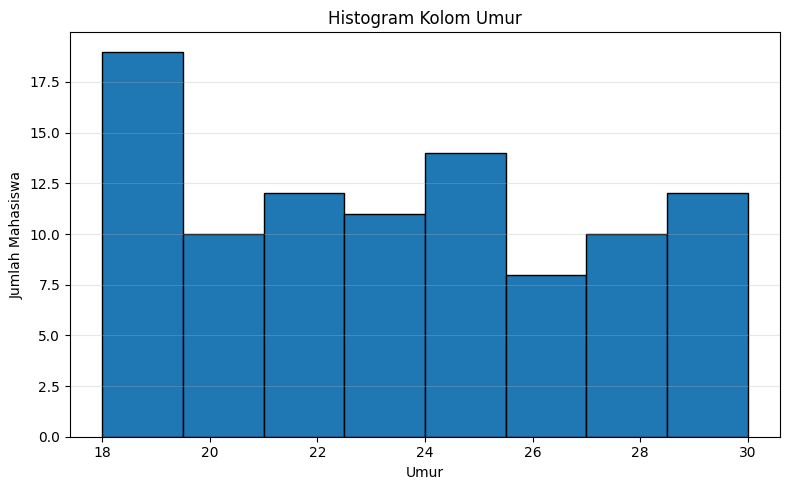

In [65]:
# Menggunakan Matplotlib
plt.figure(figsize=(8, 5))

plt.hist(
    df["Umur"].dropna(),
    bins="auto",
    edgecolor="black"
)

plt.title("Histogram Kolom Umur")
plt.xlabel("Umur")
plt.ylabel("Jumlah Mahasiswa")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

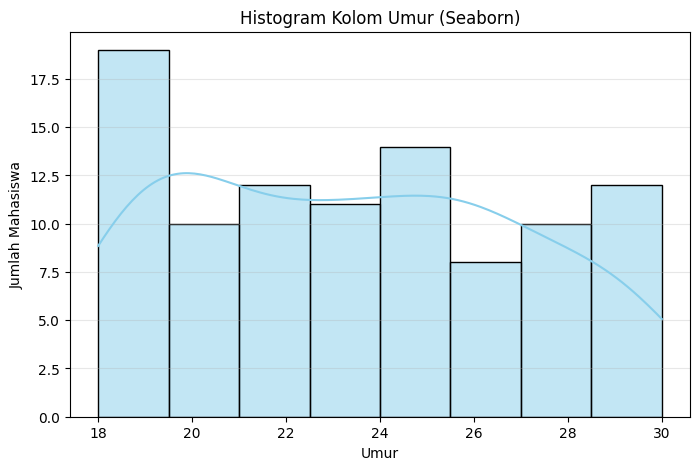

In [66]:
# Menggunakan seaborn
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Umur",
    bins="auto", kde=True,
    color="skyblue", edgecolor="black"
)

plt.title("Histogram Kolom Umur (Seaborn)")
plt.xlabel("Umur")
plt.ylabel("Jumlah Mahasiswa")
plt.grid(axis="y", alpha=0.3)

B. Grafik batang jumlah mahasiswa per Prodi

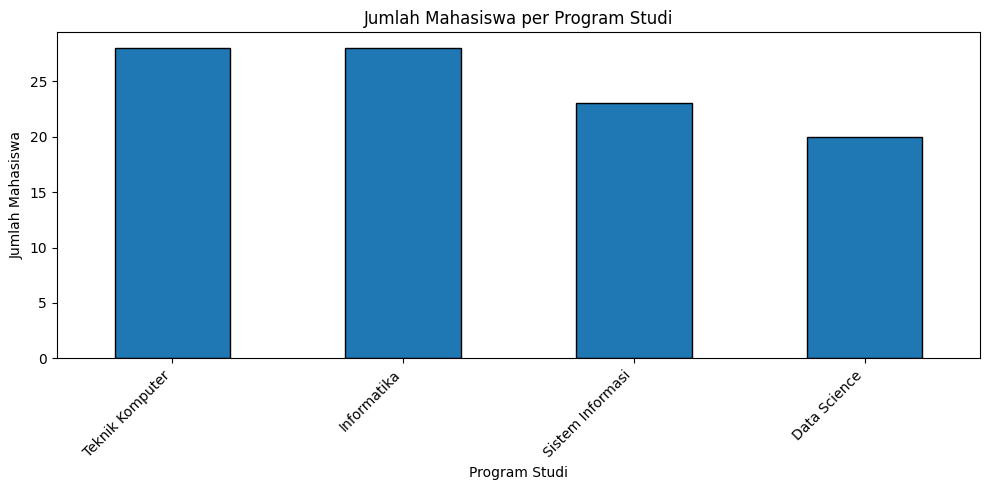

In [67]:
# Membuat salinan dataset untuk visualisasi kategori asli
df_plot = pd.read_csv("dataset_tugas1_preprocessing.csv")

# Menghitung jumlah mahasiswa pada setiap program studi
jumlah_prodi = df_plot["Prodi"].fillna("Tidak diketahui").value_counts()

# Membuat grafik batang
plt.figure(figsize=(10, 5))

jumlah_prodi.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Jumlah Mahasiswa per Program Studi")
plt.xlabel("Program Studi")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Data Preprocessing Result:

In [69]:
print("Ukuran dataset akhir:", df.shape)

print("\nTipe data akhir:")
print(df.dtypes)

print("\nMissing values akhir:")
print(df.isnull().sum())

print("\nLima baris pertama setelah data preprocessing:")
display(df.head())

Ukuran dataset akhir: (96, 8)

Tipe data akhir:
ID                       object
Nama                     object
Jenis_Kelamin            object
Prodi                    object
Status                   object
Nilai_Akhir              object
Tanggal_Ujian    datetime64[ns]
Umur                    float64
dtype: object

Missing values akhir:
ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64

Lima baris pertama setelah data preprocessing:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020-12-11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,C,2021-11-21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021-08-19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020-01-05,26.0
5,MH006,Gita,Perempuan,Teknik Komputer,Aktif,C,2021-10-15,20.0
